# 🏆 Module 10: Industry Best Practices — What Market Leaders Are Doing in Production AI (2026 Playbook)

[![Playbook](https://img.shields.io/badge/Playbook-2026%20Market%20Leaders-purple.svg)](https://ai.google.dev)
[![FinOps](https://img.shields.io/badge/Governance-LLM%20Gateway%20%7C%20Dashboards%20%7C%20Email%20Alerts-blue.svg)](https://ai.google.dev)
[![Models](https://img.shields.io/badge/Models-Gemini%204%20Argon%20%7C%203.8%20Flash%20%7C%203.5%20Flash--Lite-green.svg)](https://ai.google.dev)

> **🧠 Production Architecture Reality Check:**  
> What separates a brittle weekend AI prototype from a **mission-critical enterprise AI platform** at companies like Stripe, Uber, Goldman Sachs, Wayfair, Duolingo, and Shopify?  
> It is **NOT** a magic prompt! Market leaders engineer **5 production pillars** around their foundation models:
> 1. **Stratified Context Engineering & Trajectory Compaction** (80%+ Prefix Cache Hit Rates)
> 2. **Speculative Cascade Routing** (`gemini-3.5-flash-lite` → `gemini-3.8-flash` → `gemini-4-argon`)
> 3. **Sandboxed Execution Harnesses & Deterministic Pre/Post Hooks**
> 4. **Continuous LLM-as-a-Judge Evaluation Flywheels**
> 5. **Real-Time FinOps Dashboards & Multi-Tier User/Admin Email Alerting**

<p align="center">
  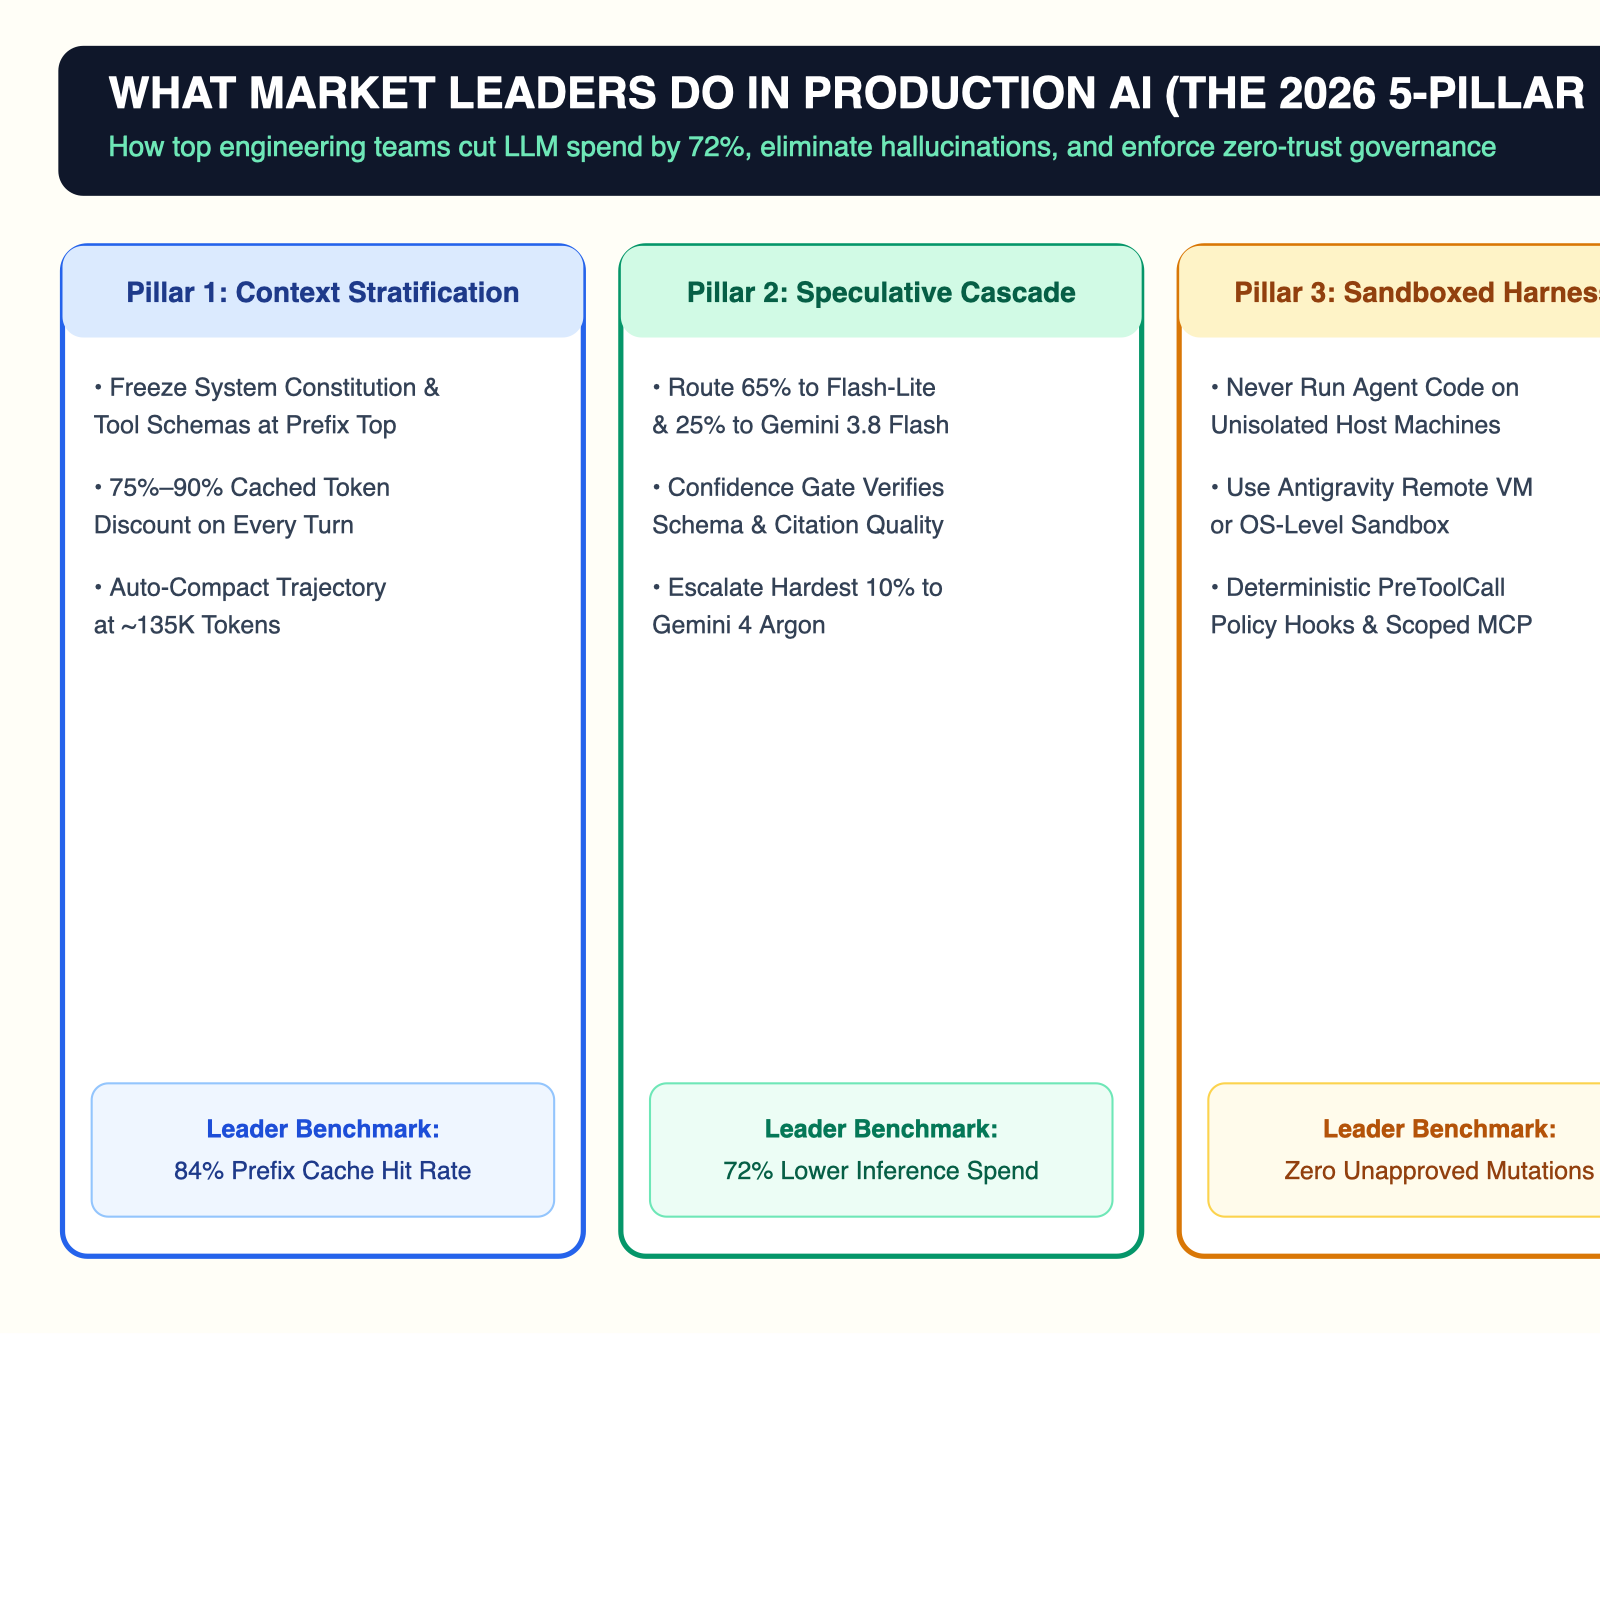
</p>

<p align="center">
  <img src="../images/enterprise_gateway_alerting_poster.jpg" alt="Enterprise LLM Gateway FinOps and Alerting Poster" width="96%" />
</p>

In [ ]:
# 1. Import the Market Leaders Playbook Engine & Enterprise Alerting Service
import sys
import os
import json

sys.path.insert(0, os.path.abspath("../06_Tokenomics_Cost_Optimization_LLM_Gateway/app"))

from market_leaders_playbook import (
    StratifiedPromptContext,
    SpeculativeCascadeEngine,
    evaluate_agent_trajectory,
)
from alerting import alerting_service
from gateway_engine import gateway_engine, GatewayRequest

print("✅ Market Leaders 5-Pillar Playbook & Alerting Engine Loaded!")

---
## 🧱 Pillar 1: Stratified Context Engineering & Automatic Compaction

### 🔥 Fireside Chat: Why Naive Prompt Concatenation Destroys Your Cloud Bill
* **Junior Engineer:** *"I put today's timestamp and the user's name on Line 1 of the system prompt, followed by our 40-page SRE manual. Why is our Gemini Context Cache hit rate 0%?!"*
* **Market-Leader Architect:** *"Because prefix caching hashes tokens from left to right! If token #5 changes on every request, the entire 40-page manual after it misses the cache. **Market leaders stratify prompts into 5 strict layers**: immutable system constitution & tool schemas at the top (cached at 75–90% discount), compacted episodic summary in the middle, and dynamic RAG chunks + user input at the very bottom!"*

In [ ]:
# Pillar 1 Demo: Stratified Prompt Compilation & Prefix Cache Economics
stratified = StratifiedPromptContext(
    layer_1_static_system_constitution=(
        "You are OmniOps Principal AI Architect. Adhere strictly to zero-trust IAM, "
        "SEBI/SOC2 audit rules, and deterministic Pydantic output schemas. " * 25
    ),
    layer_2_tool_and_mcp_schemas=(
        "Tool 1: fetch_pod_telemetry(service_name, window_m)\n"
        "Tool 2: query_hybrid_runbooks(query, top_k)\n"
        "Tool 3: dispatch_admin_circuit_breaker_alert(tenant_id, spend_usd) " * 15
    ),
    layer_3_compacted_episodic_summary="Turns 1-14 compacted at 135K threshold: User investigated payment-gateway latency.",
    layer_4_dynamic_retrieved_rag_chunks=[
        "[RB-301] Scale Cloud Run max-instances to 200 when concurrency > 80.",
        "[RB-302] Verify Cloud SQL PgBouncer pool utilization < 85%.",
    ],
    layer_5_active_user_turn="Generate the remediation plan and notify the on-call SRE.",
)

compiled = stratified.compile_cache_optimal_prompt()
print(f"📦 Cached Prefix Tokens          : {compiled['cached_prefix_tokens']:,}")
print(f"⚡ Dynamic Suffix Tokens         : {compiled['dynamic_suffix_tokens']:,}")
print(f"🎯 Prefix Cache Ratio            : {compiled['prefix_cache_ratio_pct']}%")
print(f"💰 Estimated Cost Reduction      : {compiled['estimated_cost_reduction_pct']}%")

---
## 🚦 Pillar 2: Speculative Cascade Routing (`Flash-Lite` → `3.8 Flash` → `4 Argon`)

Market leaders never send 100% of traffic to their largest frontier model. Instead, they run a **Speculative Cascade**:
1. Route lightweight classification/formatting to **`gemini-3.5-flash-lite`** ($0.075/1M input).
2. Route standard tool-calling & RAG synthesis to **`gemini-3.8-flash`** ($0.15/1M input) and check a **Confidence Gate**.
3. Escalate to **`gemini-4-argon`** ($2.00/1M input) **only** when the problem requires deep formal reasoning, complex code synthesis, or 1M Long-Decode!

In [ ]:
# Pillar 2 Demo: Speculative Cascade Router Across Workload Complexity
cascade = SpeculativeCascadeEngine()

sample_prompts = [
    "Classify this log line into INFO, WARN, or ERROR and return JSON.",
    "Summarize the top 3 root causes from the retrieved Cloud Run runbooks with citations.",
    "Prove deadlock freedom and formal safety invariants for our multi-region distributed lock manager.",
]

for p in sample_prompts:
    res = cascade.execute_with_cascade(p)
    print(f"🔹 Prompt: {p[:70]}...")
    print(f"   Hops Executed : {[h['model_id'] for h in res['cascade_hops']]}")
    print(f"   Final Model   : {res['final_model_used']} (Confidence={res['final_confidence']})")
    print(f"   Total Cost    : ${res['total_cost_usd']:.5f} (Saved {res['savings_vs_always_argon_pct']}% vs Always-Argon)\n")

---
## 🔬 Pillar 3 & 4: Automated LLM-as-a-Judge Trajectory Evaluation Flywheel

Before market leaders merge any prompt, tool schema, or model upgrade into production, their CI/CD pipeline runs an **Evaluation Flywheel** powered by **`gemini-4-argon`** as an impartial judge grading:
- **Factual Grounding Score (0–5)**: Are every single claim and number backed by retrieved context?
- **Tool Selection Precision (0.0–1.0)**: Did the agent call the right MCP tools without redundant loops?
- **Schema & Safety Compliance**: Did the output validate against Pydantic and pass PII/DLP checks?

In [ ]:
# Pillar 4 Demo: CI/CD Release Gate with Gemini 4 Argon Judge Scorecard
good_candidate = evaluate_agent_trajectory(
    trajectory_id="pr_build_2026_881_pass",
    used_citations=True,
    unnecessary_tool_loops=0,
    passed_schema=True,
)
bad_candidate = evaluate_agent_trajectory(
    trajectory_id="pr_build_2026_882_regress",
    used_citations=False,
    unnecessary_tool_loops=3,
    passed_schema=True,
)

print("✅ Candidate #1 Scorecard:", good_candidate.model_dump_json(indent=2))
print("\n🛑 Candidate #2 Scorecard:", bad_candidate.model_dump_json(indent=2))

---
## 📧 Pillar 5: Executive Dashboards, Reporting & Automated User/Admin Email Alerting

A production LLM Gateway must keep **both End Users and Platform Admins** proactively informed:
1. **End-User 80% Soft Quota Warning Email**: Sent automatically when a team reaches 80% of its token budget, showing their `thoughts_token_count` share and how to save 75–90% with Context Caching.
2. **End-User Long-Decode Completion Email**: Sent when an asynchronous `gemini-4-argon` (`background=True`) or Deep Research interaction completes.
3. **Admin 100% Circuit-Breaker Alert Email & PagerDuty Webhook**: Sent when a tenant hits 100% of its budget cap and is gracefully downgraded to `gemini-3.5-flash-lite`.
4. **SecOps Guardrail Interception Alert**: Sent immediately when prompt injection or secret exfiltration is blocked.
5. **Executive Weekly FinOps HTML Digest**: Sent to engineering leadership summarizing total spend, net savings, cache hit rates, and model tier distribution.

In [ ]:
# Pillar 5 Demo: Trigger & Inspect Live User, Admin, SecOps & Executive HTML Emails
from IPython.display import HTML, display

# 1. Trigger a User 80% Quota Warning Email
user_warn = alerting_service.send_user_quota_warning(
    user_email="principal.dev@acme.io",
    user_name="Mani Chandrasekaran",
    tenant_id="acme-core-eng",
    used_usd=42.50,
    limit_usd=50.00,
    top_model="gemini-4-argon",
    thoughts_token_pct=44.2,
)

# 2. Trigger an Admin 100% Circuit-Breaker Email
admin_cb = alerting_service.send_admin_circuit_breaker_alert(
    admin_email="finops-admin@acme.io",
    tenant_id="acme-core-eng",
    used_usd=51.20,
    limit_usd=50.00,
    action_taken="AUTO_DOWNGRADE_TO_FLASH_LITE",
    anomalous_agent_id="antigravity_sdk:gemini-4-argon",
)

# 3. Trigger an Executive FinOps Digest Email
exec_report = alerting_service.send_executive_finops_report(
    recipient_email="vp-engineering@acme.io",
    stats=gateway_engine.get_dashboard_summary(),
)

print(f"📬 Total Emails & Alerts in Outbox: {len(alerting_service.outbox)}")
for a in alerting_service.outbox[:4]:
    print(f" • [{a.recipient_role}] {a.alert_type} -> {a.recipient_email} | Subject: {a.subject}")

# Render the Executive FinOps HTML Email inline inside the Notebook!
display(HTML(exec_report.html_body))